# xBD Data Cleaning and EDA

This notebook only inspects and cleans already-downloaded xBD data. It does not create data splits, train models, evaluate models, or modify the source dataset.

The split assignment is read from `data/splits.csv`; the separate `scripts/prepare_splits.py` script owns split creation.

## 1. Configuration and Imports

In [ ]:
from pathlib import Path
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt
from shapely.geometry import shape

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / 'data').exists():
    REPO_ROOT = Path('..').resolve()
XBD_DIR = REPO_ROOT / 'xbd'
SPLITS = REPO_ROOT / 'data' / 'splits.csv'
OUTPUT_DIR = REPO_ROOT / 'results' / 'eda'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42
IMAGE_SAMPLE_SIZE = 12
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Repository: {REPO_ROOT}')
print(f'xBD directory: {XBD_DIR}')

Repository: C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping
xBD directory: C:\Users\bhvns\Documents\University of Konstanz\Courses\satellite-disaster-damage-mapping\xbd


## 2. Input Inventory and Existing Splits

In [2]:
if not SPLITS.exists():
    raise FileNotFoundError(f'Missing existing split index: {SPLITS}')
if not XBD_DIR.exists():
    raise FileNotFoundError(f'Missing downloaded xBD directory: {XBD_DIR}')

splits_df = pd.read_csv(SPLITS)
required_columns = {'name', 'path', 'subdir', 'scene_id', 'disaster', 'kind', 'origin', 'split'}
missing_columns = required_columns - set(splits_df.columns)
if missing_columns:
    raise ValueError(f'splits.csv is missing columns: {sorted(missing_columns)}')

splits_df['resolved_path'] = splits_df['path'].astype(str).map(lambda value: REPO_ROOT / Path(value.replace('\\', '/')))
splits_df['exists'] = splits_df['resolved_path'].map(Path.exists)
inventory = splits_df.groupby(['split', 'subdir', 'kind']).size().unstack(fill_value=0)
print(f'Indexed files: {len(splits_df):,}')
print(f'Unique scenes: {splits_df.scene_id.nunique():,}')
print(f'Existing files: {splits_df.exists.sum():,} / {len(splits_df):,}')
display(inventory)
if not splits_df['exists'].all():
    display(splits_df.loc[~splits_df['exists'], ['path', 'split', 'kind']].head(20))

Indexed files: 77,238
Unique scenes: 11,034
Existing files: 77,238 / 77,238


kind             post_disaster  post_disaster_rgb  pre_disaster
split    subdir                                                
test_id  images           1135                  0          1135
         labels           1135                  0          1135
         masks            1135               1135          1135
test_ood images           6372                  0          6372
         labels           6372                  0          6372
         masks            6372               6372          6372
train    images           3135                  0          3135
         labels           3135                  0          3135
         masks            3135               3135          3135
val      images            392                  0           392
         labels            392                  0           392
         masks             392                392           392

In [17]:
scene_summary = splits_df.groupby('scene_id').agg(
    disaster=('disaster', 'first'),
    split=('split', 'first'),
    indexed_files=('name', 'size'),
    existing_files=('exists', 'sum'),
).reset_index()
scene_summary['complete_index_entry'] = scene_summary['indexed_files'].eq(scene_summary['existing_files'])
scene_summary['scene_key_consistent'] = splits_df.groupby('scene_id')['split'].nunique().eq(1).reindex(scene_summary.scene_id).to_numpy()
required_scene_roles = {('images', 'pre_disaster'), ('images', 'post_disaster'), ('labels', 'pre_disaster'), ('labels', 'post_disaster'), ('masks', 'pre_disaster'), ('masks', 'post_disaster')}
roles_by_scene = splits_df.groupby('scene_id').apply(lambda frame: set(zip(frame['subdir'], frame['kind'])), include_groups=False)
scene_summary['required_roles_present'] = scene_summary['scene_id'].map(lambda scene_id: required_scene_roles.issubset(roles_by_scene.get(scene_id, set())))
print('Scenes by split:')
display(scene_summary.groupby(['split', 'disaster']).size().unstack(fill_value=0))
print('Scene-level integrity checks:')
display(scene_summary[['complete_index_entry', 'scene_key_consistent', 'required_roles_present']].value_counts().rename('scenes'))
scene_summary.to_csv(OUTPUT_DIR / 'scene_summary.csv', index=False)

Scenes by split:


disaster,guatemala-volcano,hurricane-florence,hurricane-harvey,hurricane-matthew,hurricane-michael,joplin-tornado,lower-puna-volcano,mexico-earthquake,midwest-flooding,moore-tornado,nepal-flooding,palu-tsunami,pinery-bushfire,portugal-wildfire,santa-rosa-wildfire,socal-fire,sunda-tsunami,tuscaloosa-tornado,woolsey-fire
split,,,,,,,,,,,,,,,,,,,
test_id,10,227,203,167,207,0,0,72,166,0,0,83,0,0,0,0,0,0,0
test_ood,0,0,0,0,0,0,0,0,0,0,0,0,1845,1869,377,1403,0,0,878
train,16,283,283,212,305,132,259,108,248,202,550,100,0,0,0,0,132,305,0
val,2,36,36,26,38,17,32,13,31,25,69,13,0,0,0,0,16,38,0


Scene-level integrity checks:


complete_index_entry  scene_key_consistent  required_roles_present
True                  True                  True                      11034
Name: scenes, dtype: int64

## 3. Split Audit and Training EDA

Split-level tables and charts below are audit outputs for the existing assignments. Exploratory analysis of damage, geometry, image quality, and examples is restricted to the training split; validation and test data are never used to guide EDA.

Post-disaster label files available: 11,034
Label files by disaster:


split,test_id,test_ood,train,val
disaster,,,,
guatemala-volcano,10,0,16,2
hurricane-florence,227,0,283,36
hurricane-harvey,203,0,283,36
hurricane-matthew,167,0,212,26
hurricane-michael,207,0,305,38
joplin-tornado,0,0,132,17
lower-puna-volcano,0,0,259,32
mexico-earthquake,72,0,108,13
midwest-flooding,166,0,248,31


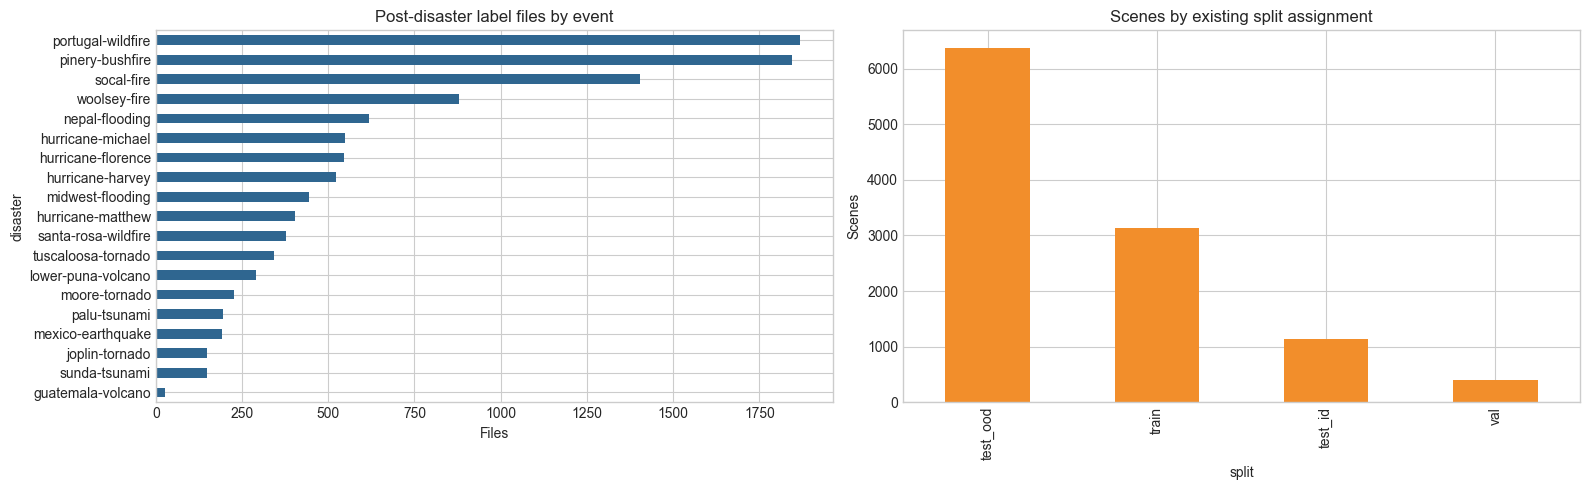

In [4]:
label_index = splits_df[(splits_df['subdir'] == 'labels') & (splits_df['kind'] == 'post_disaster') & splits_df['exists']].copy()
print(f'Post-disaster label files available: {len(label_index):,}')
print('Label files by disaster:')
display(label_index.groupby(['disaster', 'split']).size().unstack(fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
label_index['disaster'].value_counts().sort_values().plot.barh(ax=axes[0], color='#2f6690')
axes[0].set_title('Post-disaster label files by event')
axes[0].set_xlabel('Files')
split_counts = splits_df.drop_duplicates('scene_id')['split'].value_counts()
split_counts.plot.bar(ax=axes[1], color='#f28e2b')
axes[1].set_title('Scenes by existing split assignment')
axes[1].set_ylabel('Scenes')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'event_and_split_counts.png', dpi=150)
plt.show()

In [19]:
def read_label_features(label_path):
    with label_path.open(encoding='utf-8') as handle:
        data = json.load(handle)
    features = data.get('features', [])
    if isinstance(features, dict):
        features = features.get('lng_lat', [])
    return data, features


def feature_geometry(feature):
    if feature.get('geometry'):
        return shape(feature['geometry'])
    if feature.get('wkt'):
        return wkt.loads(feature['wkt'])
    return None


class_counts = Counter()
class_by_event_split = Counter()
feature_counts = []
geometry_stats = []
invalid_geometry_count = 0
missing_subtype_count = 0

for row in label_index.itertuples(index=False):
    data, features = read_label_features(row.resolved_path)
    feature_counts.append({'scene_id': row.scene_id, 'disaster': row.disaster, 'split': row.split, 'buildings': len(features)})
    for index, feature in enumerate(features):
        properties = feature.get('properties', {})
        damage_class = properties.get('subtype', 'missing')
        class_counts[damage_class] += 1
        class_by_event_split[(row.disaster, row.split, damage_class)] += 1
        missing_subtype_count += damage_class == 'missing'
        geometry = feature_geometry(feature)
        if geometry is None or geometry.is_empty or not geometry.is_valid:
            invalid_geometry_count += 1
            continue
        minx, miny, maxx, maxy = geometry.bounds
        geometry_stats.append({
            'scene_id': row.scene_id,
            'disaster': row.disaster,
            'split': row.split,
            'damage_class': damage_class,
            'bbox_width_deg': maxx - minx,
            'bbox_height_deg': maxy - miny,
            'area_deg2': geometry.area,
        })

feature_counts_df = pd.DataFrame(feature_counts)
class_counts_df = pd.DataFrame(class_counts.items(), columns=['damage_class', 'count']).sort_values('count', ascending=False)
class_by_event_split_df = pd.DataFrame([
    {'disaster': disaster, 'split': split, 'damage_class': damage_class, 'count': count}
    for (disaster, split, damage_class), count in class_by_event_split.items()
])
geometry_stats_df = pd.DataFrame(geometry_stats)
train_feature_counts_df = feature_counts_df[feature_counts_df['split'] == 'train'].copy()
train_geometry_stats_df = geometry_stats_df[geometry_stats_df['split'] == 'train'].copy()
train_class_counts_df = (class_by_event_split_df[class_by_event_split_df['split'] == 'train']
                         .groupby('damage_class', as_index=False)['count'].sum()
                         .sort_values('count', ascending=False))
print(f'Buildings inspected across all splits: {class_counts_df["count"].sum():,}')
print(f'Train buildings used for EDA: {train_class_counts_df["count"].sum():,}')
print(f'Invalid or missing geometries across all splits: {invalid_geometry_count:,}')
print(f'Missing damage subtypes across all splits: {missing_subtype_count:,}')
print('Training damage classes:')
display(train_class_counts_df)
class_counts_df.to_csv(OUTPUT_DIR / 'damage_class_counts_all_splits.csv', index=False)
class_by_event_split_df.to_csv(OUTPUT_DIR / 'damage_class_by_event_split.csv', index=False)
feature_counts_df.to_csv(OUTPUT_DIR / 'buildings_per_scene_all_splits.csv', index=False)
geometry_stats_df.to_csv(OUTPUT_DIR / 'footprint_geometry_all_splits.csv', index=False)
train_class_counts_df.to_csv(OUTPUT_DIR / 'damage_class_counts_train.csv', index=False)

Buildings inspected across all splits: 425,368
Train buildings used for EDA: 225,506
Invalid or missing geometries across all splits: 0
Missing damage subtypes across all splits: 0
Training damage classes:


,damage_class,count
3,no-damage,162462
2,minor-damage,21764
1,major-damage,18976
0,destroyed,14017
4,un-classified,8287


## 4. Cleaning Diagnostics

The checks below document what would be excluded from supervised analysis: unclassified annotations, missing/invalid geometry, and degenerate footprints. Nothing is silently deleted from the downloaded dataset.

In [18]:
cleaning_summary = pd.DataFrame([
    {'check': 'indexed files missing on disk', 'count': int((~splits_df['exists']).sum()), 'action': 'report; source data unchanged'},
    {'check': 'scenes with incomplete file index', 'count': int((~scene_summary['complete_index_entry']).sum()), 'action': 'report; source data unchanged'},
    {'check': 'scenes assigned to multiple splits', 'count': int((~scene_summary['scene_key_consistent']).sum()), 'action': 'report; source data unchanged'},
    {'check': 'scenes missing a pre/post image-label-mask role', 'count': int((~scene_summary['required_roles_present']).sum()), 'action': 'report; source data unchanged'},
    {'check': 'un-classified annotations', 'count': int(class_counts.get('un-classified', 0)), 'action': 'exclude from four-class modeling'},
    {'check': 'missing damage subtype', 'count': int(missing_subtype_count), 'action': 'exclude from four-class modeling'},
    {'check': 'invalid or missing geometries', 'count': int(invalid_geometry_count), 'action': 'exclude from spatial/crop analysis'},
])
cleaning_summary['percent_of_relevant_rows'] = np.nan
cleaning_summary.to_csv(OUTPUT_DIR / 'cleaning_summary.csv', index=False)
display(cleaning_summary)

unclassified_by_split = class_by_event_split_df[class_by_event_split_df['damage_class'] == 'un-classified'].groupby('split')['count'].sum()
all_by_split = class_by_event_split_df.groupby('split')['count'].sum()
unclassified_rates = pd.DataFrame({'unclassified': unclassified_by_split, 'all_annotations': all_by_split}).fillna(0)
unclassified_rates['percent'] = 100 * unclassified_rates['unclassified'] / unclassified_rates['all_annotations']
print('Unclassified annotation rate by split:')
display(unclassified_rates.round(2))
unclassified_rates.to_csv(OUTPUT_DIR / 'unclassified_rate_by_split.csv')

,check,count,action,percent_of_relevant_rows
0,indexed files missing on disk,0,report; source data unchanged,NaN
1,scenes with incomplete file index,0,report; source data unchanged,NaN
2,scenes assigned to multiple splits,0,report; source data unchanged,NaN
3,scenes missing a pre/post image-label-mask role,0,report; source data unchanged,NaN
4,un-classified annotations,14011,exclude from four-class modeling,NaN
5,missing damage subtype,0,exclude from four-class modeling,NaN
6,invalid or missing geometries,0,exclude from spatial/crop analysis,NaN


Unclassified annotation rate by split:


,unclassified,all_annotations,percent
split,,,
test_id,1915,91755,2.09
test_ood,2553,77313,3.30
train,8287,225506,3.67
val,1256,30794,4.08


Training footprint geometry summary (coordinates are longitude/latitude degrees):


,bbox_width_deg,bbox_height_deg,area_deg2
count,225506.000000,225506.000000,2.255060e+05
mean,0.000153,0.000135,2.000000e-08
std,0.000107,0.000090,4.000000e-08
min,0.000006,0.000006,0.000000e+00
50%,0.000134,0.000120,1.000000e-08
90%,0.000256,0.000224,3.000000e-08
95%,0.000305,0.000267,5.000000e-08
99%,0.000513,0.000450,1.200000e-07
max,0.004091,0.003091,6.280000e-06


Training footprint size by damage class:


,count,mean,std,min,50%,90%,99%,max
damage_class,,,,,,,,
destroyed,14017.0,0.000131,0.000090,0.000022,0.000108,0.000226,0.000456,0.001398
major-damage,18976.0,0.000196,0.000136,0.000023,0.000181,0.000305,0.000664,0.003701
minor-damage,21764.0,0.000175,0.000107,0.000022,0.000162,0.000275,0.000537,0.002933
no-damage,162462.0,0.000169,0.000114,0.000020,0.000152,0.000270,0.000580,0.004091
un-classified,8287.0,0.000122,0.000084,0.000020,0.000106,0.000202,0.000399,0.001713


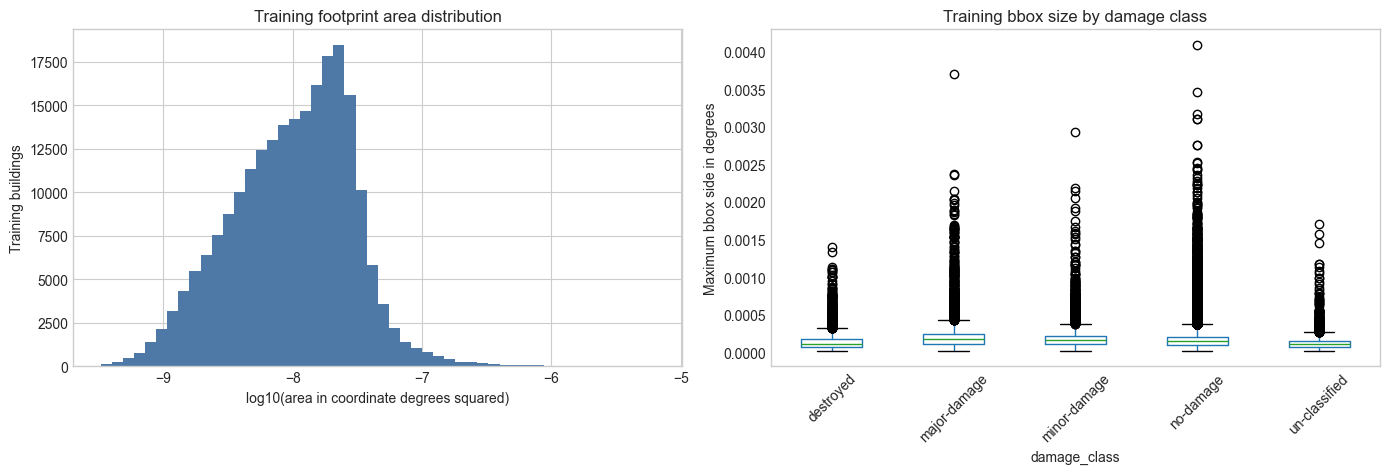

In [23]:
train_geometry_stats_df['bbox_max_deg'] = train_geometry_stats_df[['bbox_width_deg', 'bbox_height_deg']].max(axis=1)
print('Training footprint geometry summary (coordinates are longitude/latitude degrees):')
display(train_geometry_stats_df[['bbox_width_deg', 'bbox_height_deg', 'area_deg2']].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(8))
print('Training footprint size by damage class:')
display(train_geometry_stats_df.groupby('damage_class')['bbox_max_deg'].describe(percentiles=[0.5, 0.9, 0.99]).round(8))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(np.log10(train_geometry_stats_df['area_deg2'].clip(lower=1e-12)), bins=50, color='#4e79a7')
axes[0].set_title('Training footprint area distribution')
axes[0].set_xlabel('log10(area in coordinate degrees squared)')
axes[0].set_ylabel('Training buildings')
train_geometry_stats_df.boxplot(column='bbox_max_deg', by='damage_class', ax=axes[1], grid=False, rot=45)
axes[1].set_title('Training bbox size by damage class')
axes[1].set_ylabel('Maximum bbox side in degrees')
fig.suptitle('')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_footprint_geometry_eda.png', dpi=150)
plt.show()

Training damage-class counts by event:


damage_class,no-damage,minor-damage,major-damage,destroyed,un-classified
disaster,,,,,
guatemala-volcano,514.0,9.0,9.0,25.0,174.0
hurricane-florence,3880.0,117.0,1179.0,54.0,279.0
hurricane-harvey,10494.0,2376.0,7437.0,356.0,207.0
hurricane-matthew,2326.0,5443.0,1831.0,1888.0,728.0
hurricane-michael,12895.0,4551.0,1727.0,690.0,213.0
joplin-tornado,7186.0,1901.0,881.0,2842.0,545.0
lower-puna-volcano,1994.0,49.0,26.0,438.0,504.0
mexico-earthquake,28615.0,106.0,13.0,1.0,63.0
midwest-flooding,6595.0,111.0,105.0,67.0,245.0


Training damage-class percentages by event:


damage_class,no-damage,minor-damage,major-damage,destroyed,un-classified
disaster,,,,,
guatemala-volcano,70.31,1.23,1.23,3.42,23.80
hurricane-florence,70.43,2.12,21.40,0.98,5.06
hurricane-harvey,50.28,11.38,35.63,1.71,0.99
hurricane-matthew,19.04,44.56,14.99,15.46,5.96
hurricane-michael,64.23,22.67,8.60,3.44,1.06
joplin-tornado,53.81,14.23,6.60,21.28,4.08
lower-puna-volcano,66.22,1.63,0.86,14.55,16.74
mexico-earthquake,99.36,0.37,0.05,0.00,0.22
midwest-flooding,92.59,1.56,1.47,0.94,3.44


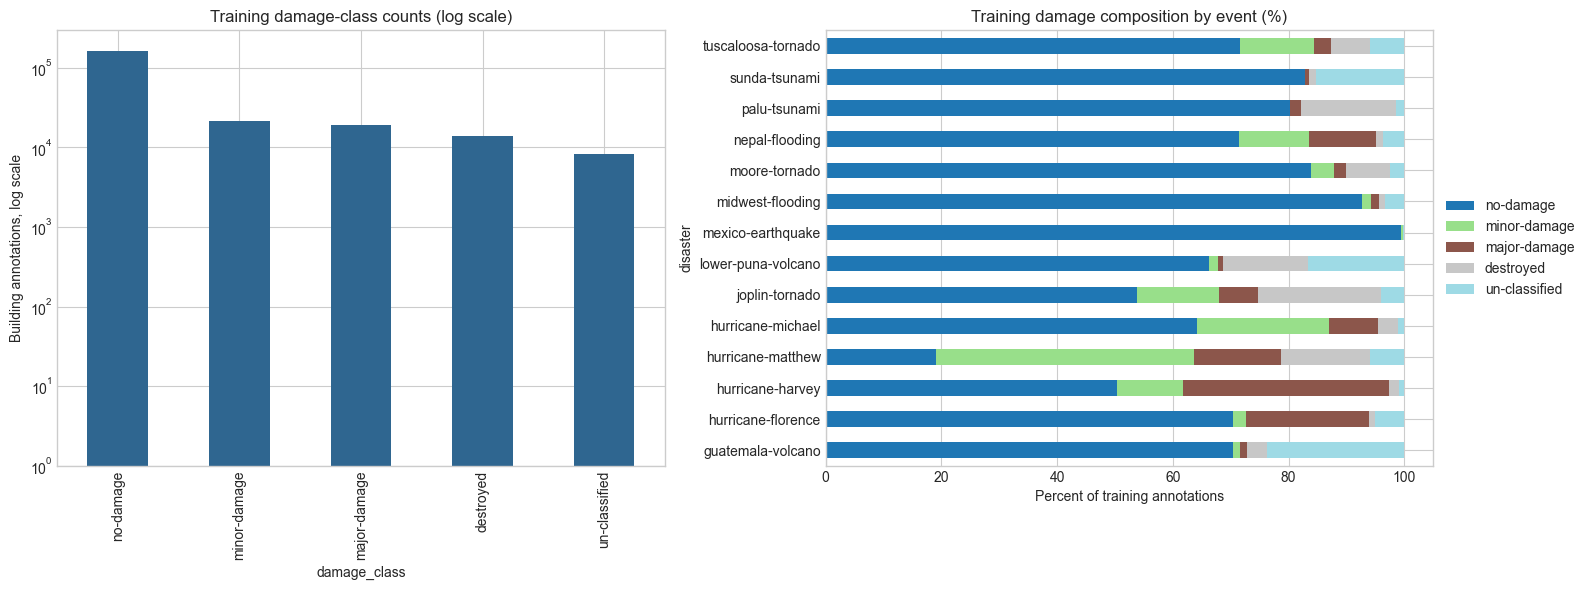

In [21]:
damage_order = ['no-damage', 'minor-damage', 'major-damage', 'destroyed', 'un-classified', 'missing']
train_class_by_event = class_by_event_split_df[class_by_event_split_df['split'] == 'train']
train_class_table = train_class_by_event.pivot_table(index='disaster', columns='damage_class', values='count', fill_value=0)
train_class_table = train_class_table.reindex(columns=[name for name in damage_order if name in train_class_table.columns], fill_value=0)
train_class_percent = train_class_table.div(train_class_table.sum(axis=1), axis=0).mul(100).round(2)
print('Training damage-class counts by event:')
display(train_class_table)
print('Training damage-class percentages by event:')
display(train_class_percent)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
train_class_counts_df.set_index('damage_class')['count'].reindex(damage_order).dropna().plot.bar(ax=axes[0], color='#2f6690', log=True)
axes[0].set_title('Training damage-class counts (log scale)')
axes[0].set_ylabel('Building annotations, log scale')
train_class_percent.plot.barh(stacked=True, ax=axes[1], colormap='tab20')
axes[1].set_title('Training damage composition by event (%)')
axes[1].set_xlabel('Percent of training annotations')
axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_class_counts_log_and_composition.png', dpi=150)
plt.show()

### Split-composition audit

This comparison uses all existing splits only to verify the inherited split design. It is not used as exploratory analysis or to make cleaning decisions.

Split-level class counts (audit only):


damage_class,no-damage,minor-damage,major-damage,destroyed,un-classified
split,,,,,
test_id,65781,11040,8364,4655,1915
test_ood,61992,704,726,11338,2553
train,162462,21764,18976,14017,8287
val,22798,3352,1838,1550,1256


Split-level class composition (%; audit only):


damage_class,no-damage,minor-damage,major-damage,destroyed,un-classified
split,,,,,
test_id,71.69,12.03,9.12,5.07,2.09
test_ood,80.18,0.91,0.94,14.67,3.30
train,72.04,9.65,8.41,6.22,3.67
val,74.03,10.89,5.97,5.03,4.08


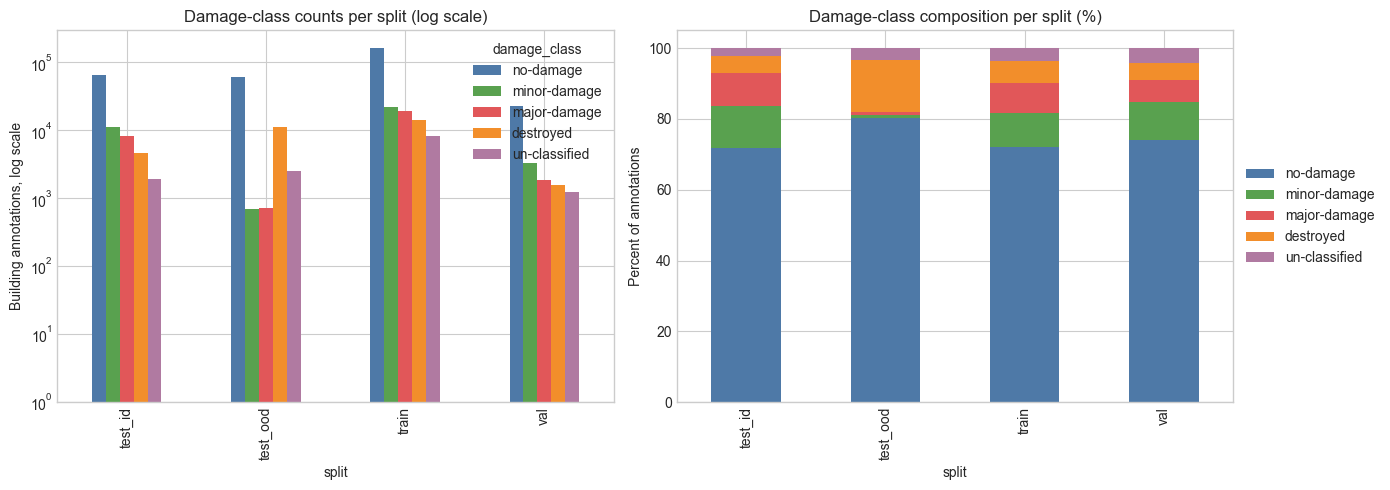

In [22]:
split_class_table = class_by_event_split_df.pivot_table(index='split', columns='damage_class', values='count', aggfunc='sum', fill_value=0)
split_class_table = split_class_table.reindex(columns=[name for name in damage_order if name in split_class_table.columns], fill_value=0)
split_class_percent = split_class_table.div(split_class_table.sum(axis=1), axis=0).mul(100).round(2)
print('Split-level class counts (audit only):')
display(split_class_table)
print('Split-level class composition (%; audit only):')
display(split_class_percent)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
split_class_table.plot.bar(ax=axes[0], log=True, color=['#4e79a7', '#59a14f', '#e15759', '#f28e2b', '#b07aa1'])
axes[0].set_title('Damage-class counts per split (log scale)')
axes[0].set_ylabel('Building annotations, log scale')
split_class_percent.plot.bar(stacked=True, ax=axes[1], color=['#4e79a7', '#59a14f', '#e15759', '#f28e2b', '#b07aa1'])
axes[1].set_title('Damage-class composition per split (%)')
axes[1].set_ylabel('Percent of annotations')
axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'damage_class_counts_per_split_log.png', dpi=150)
fig.savefig(OUTPUT_DIR / 'damage_class_composition_per_split.png', dpi=150)
plt.show()
split_class_table.to_csv(OUTPUT_DIR / 'damage_class_counts_per_split.csv')
split_class_percent.to_csv(OUTPUT_DIR / 'damage_class_composition_per_split.csv')

## 5. Cross-Split Cleaning and Acquisition QC

The following checks are cleaning and quality-control diagnostics applied across all existing splits. They do not serve as exploratory analysis and do not change the files.

In [6]:
image_index = splits_df[(splits_df['subdir'] == 'images') & splits_df['exists']].copy()
image_index['image_size'] = image_index['resolved_path'].map(lambda path: Image.open(path).size)
image_index['width'] = image_index['image_size'].map(lambda size: size[0])
image_index['height'] = image_index['image_size'].map(lambda size: size[1])
print('Image dimensions:')
display(image_index.groupby(['width', 'height']).size().rename('files').reset_index())
print('Image dimensions by image kind:')
display(image_index.groupby(['kind', 'width', 'height']).size().rename('files').reset_index())
image_index[['name', 'split', 'disaster', 'kind', 'width', 'height']].to_csv(OUTPUT_DIR / 'image_metadata.csv', index=False)

Image dimensions:


,width,height,files
0,1024,1024,22068


Image dimensions by image kind:


,kind,width,height,files
0,post_disaster,1024,1024,11034
1,pre_disaster,1024,1024,11034


Acquisition metadata records inspected: 400


gsd                                           off_nadir_angle  \
          count  mean   std   min   25%   50%   75%   max           count   
split                                                                       
test_id    39.0  2.29  0.58  1.25  2.07  2.09  2.92  3.02            39.0   
test_ood  242.0  2.12  0.32  1.66  1.77  2.23  2.23  2.57           242.0   
train     103.0  2.25  0.48  1.25  1.86  2.24  2.51  3.02           103.0   
val        16.0  2.33  0.49  1.25  2.02  2.34  2.77  3.02            16.0   

                 ...               sun_elevation                              \
           mean  ...    75%    max         count   mean    std    min    25%   
split            ...                                                           
test_id   31.74  ...  40.49  42.91          39.0  61.90   7.34  50.76  53.72   
test_ood  26.01  ...  30.85  32.67         242.0  55.06  16.07  34.94  35.89   
train     28.32  ...  34.26  42.91         103.0  65.22   7.26  50.76  60.16   
val       29.79  ...  36.07  42.91          16.0  66.22   6.70  50.76  64.80   

                               
            50%    75%    max  
split                          
test_id   63.01  66.45  72.46  
test_ood  62.01  71.46  71.46  
train     66.97  71.38  72.46  
val       67.92  71.38  72.40  

[4 rows x 24 columns]

gsd  off_nadir_angle  sun_elevation
disaster            split                                         
guatemala-volcano   train     1.41            21.97          71.18
hurricane-florence  test_id   2.09            28.02          53.72
                    train     2.09            28.02          53.72
                    val       2.09            28.02          53.72
hurricane-harvey    test_id   3.02            42.91          66.45
                    train     3.02            42.91          66.45
                    val       3.02            42.91          66.45
hurricane-matthew   test_id   1.91            32.08          61.83
                    train     2.67            34.41          60.27
                    val       2.77            36.07          59.83
hurricane-michael   test_id   2.07            28.87          50.76
                    train     2.07            28.87          50.76
                    val       2.07            28.87          50.76
joplin-tornado      train     2.35            28.43          71.85
                    val       2.35            28.43          71.85
lower-puna-volcano  train     2.24            25.81          71.92
                    val       2.24            25.81          71.92
mexico-earthquake   test_id   2.65            34.38          68.67
                    train     2.65            34.38          68.67
                    val       2.65            34.38          68.67
midwest-flooding    test_id   1.28             9.91          72.41
                    train     1.27             9.35          72.41
                    val       1.25             7.11          72.40
moore-tornado       train     1.73            13.55          70.26
nepal-flooding      train     2.57            37.13          67.04
                    val       2.55            36.84          67.03
palu-tsunami        test_id   2.82            36.44          68.85
                    train     2.82            36.44          68.85
                    val       2.82            36.44          68.85
pinery-bushfire     test_ood  1.82            25.07          65.28
portugal-wildfire   test_ood  2.23            25.35          71.46
santa-rosa-wildfire test_ood  1.88            21.35          43.56
socal-fire          test_ood  2.57            32.67          35.89
sunda-tsunami       train     1.77            16.38          60.16
tuscaloosa-tornado  train     1.86            20.65          71.38
                    val       1.86            20.65          71.38
woolsey-fire        test_ood  1.85            19.37          34.94

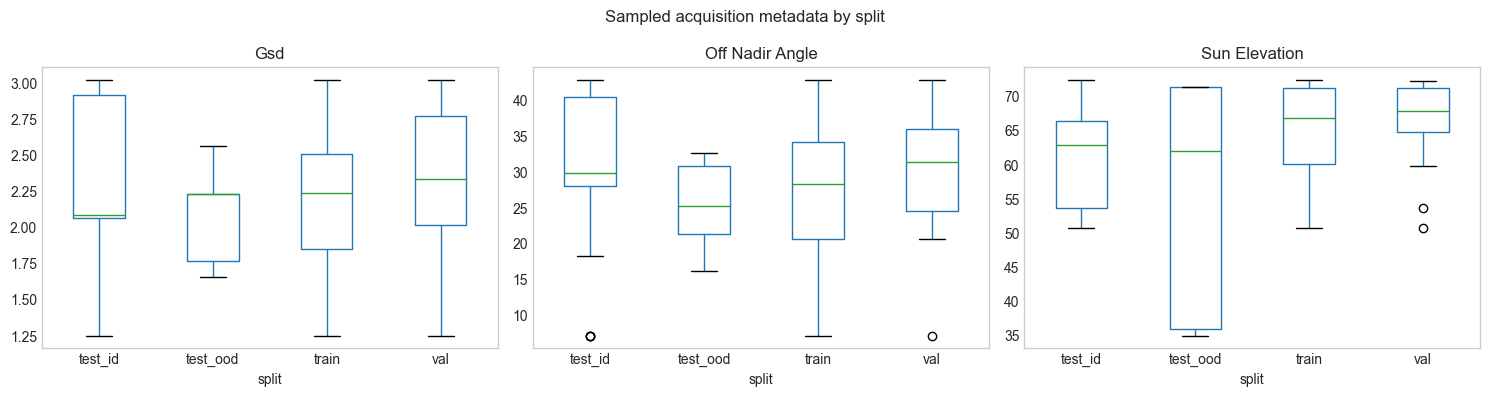

In [15]:
metadata_sample = label_index.sample(min(400, len(label_index)), random_state=RANDOM_SEED)
metadata_rows = []
for row in metadata_sample.itertuples(index=False):
    data, _ = read_label_features(row.resolved_path)
    metadata = data.get('metadata', {})
    metadata_rows.append({
        'scene_id': row.scene_id,
        'disaster': row.disaster,
        'split': row.split,
        'sensor': metadata.get('sensor'),
        'provider_asset_type': metadata.get('provider_asset_type'),
        'gsd': metadata.get('gsd'),
        'capture_date': metadata.get('capture_date'),
        'off_nadir_angle': metadata.get('off_nadir_angle'),
        'sun_elevation': metadata.get('sun_elevation'),
        'disaster_type': metadata.get('disaster_type'),
    })
metadata_df = pd.DataFrame(metadata_rows)
for column in ['gsd', 'off_nadir_angle', 'sun_elevation']:
    metadata_df[column] = pd.to_numeric(metadata_df[column], errors='coerce')
print(f'Acquisition metadata records inspected: {len(metadata_df):,}')
display(metadata_df.groupby('split')[['gsd', 'off_nadir_angle', 'sun_elevation']].describe().round(2))
display(metadata_df.groupby(['disaster', 'split'])[['gsd', 'off_nadir_angle', 'sun_elevation']].mean().round(2))
metadata_df.to_csv(OUTPUT_DIR / 'acquisition_metadata_sample.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column in zip(axes, ['gsd', 'off_nadir_angle', 'sun_elevation']):
    metadata_df.boxplot(column=column, by='split', ax=axis, grid=False)
    axis.set_title(column.replace('_', ' ').title())
fig.suptitle('Sampled acquisition metadata by split')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'acquisition_metadata_sample.png', dpi=150)
plt.show()

## 6. Image Quality Diagnostics

Image-quality scenes inspected: 400
Flagged for manual review: 0


mean_brightness                        brightness_std             \
                    mean     median         max           mean     median   
split                                                                       
test_id        77.467003  78.560997  116.956001         26.414  26.058001   
test_ood       80.942001  82.349998  160.498001         25.816  24.153000   
train          77.709000  77.842003  166.001007         28.799  27.941999   
val            81.863998  86.367996  106.481003         25.423  25.715000   

                    dark_fraction               bright_fraction                \
                max          mean median    max            mean median    max   
split                                                                           
test_id   54.042000         0.025    0.0  0.452           0.000    0.0  0.004   
test_ood  63.340000         0.035    0.0  0.626           0.000    0.0  0.011   
train     96.637001         0.058    0.0  0.883           0.004    0.0  0.410   
val       42.344002         0.016    0.0  0.183           0.000    0.0  0.001   

         edge_proxy                   quality_flag                
               mean median        max         mean median    max  
split                                                             
test_id       8.472  8.228  15.328000          0.0    0.0  False  
test_ood      9.139  8.754  37.700001          0.0    0.0  False  
train         7.497  7.530  20.406000          0.0    0.0  False  
val           7.954  7.731  13.181000          0.0    0.0  False

,scene_id,disaster,split,mean_brightness,brightness_std,dark_fraction,bright_fraction,edge_proxy,quality_flag


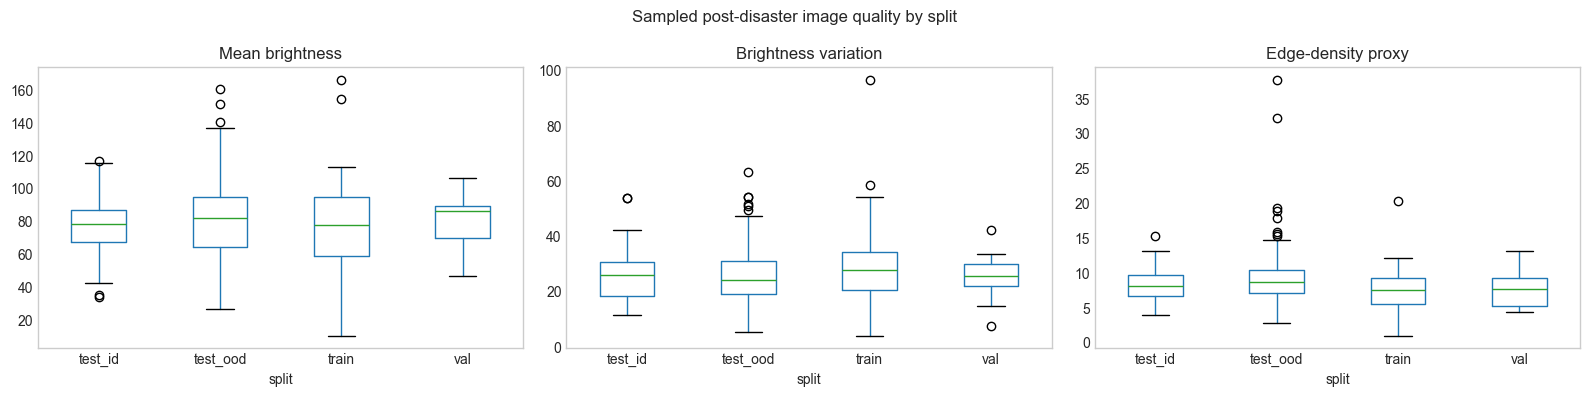

In [13]:
qc_scenes = image_index[image_index['kind'] == 'post_disaster'].drop_duplicates('scene_id')
qc_scenes = qc_scenes.sample(min(400, len(qc_scenes)), random_state=RANDOM_SEED)
quality_rows = []
for row in qc_scenes.itertuples(index=False):
    with Image.open(row.resolved_path).convert('RGB') as image:
        pixels = np.asarray(image, dtype=np.float32)
    gray = pixels.mean(axis=2)
    quality_rows.append({
        'scene_id': row.scene_id,
        'disaster': row.disaster,
        'split': row.split,
        'mean_brightness': gray.mean(),
        'brightness_std': gray.std(),
        'dark_fraction': (gray < 6).mean(),
        'bright_fraction': (gray > 250).mean(),
        'edge_proxy': np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean(),
    })
quality_df = pd.DataFrame(quality_rows)
quality_df['quality_flag'] = (quality_df['dark_fraction'] > 0.98) | (quality_df['bright_fraction'] > 0.98) | (quality_df['brightness_std'] < 3)
print(f'Image-quality scenes inspected: {len(quality_df):,}')
print(f'Flagged for manual review: {quality_df.quality_flag.sum():,}')
display(quality_df.groupby('split')[['mean_brightness', 'brightness_std', 'dark_fraction', 'bright_fraction', 'edge_proxy', 'quality_flag']].agg(['mean', 'median', 'max']).round(3))
display(quality_df[quality_df.quality_flag].head(20))
quality_df.to_csv(OUTPUT_DIR / 'image_quality_sample.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
quality_df.boxplot(column='mean_brightness', by='split', ax=axes[0], grid=False)
quality_df.boxplot(column='brightness_std', by='split', ax=axes[1], grid=False)
quality_df.boxplot(column='edge_proxy', by='split', ax=axes[2], grid=False)
for axis, title in zip(axes, ['Mean brightness', 'Brightness variation', 'Edge-density proxy']):
    axis.set_title(title)
fig.suptitle('Sampled post-disaster image quality by split')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'image_quality_sample.png', dpi=150)
plt.show()

## 7. Near-Duplicate Spot Check

A small perceptual-hash screen can flag suspiciously similar post-disaster tiles across splits. It is a review aid, not proof of geographic leakage.

In [14]:
def dhash_bits(path, hash_size=8):
    with Image.open(path).convert('L') as image:
        pixels = np.asarray(image.resize((hash_size + 1, hash_size), Image.Resampling.BILINEAR), dtype=np.int16)
    return ''.join('1' if bit else '0' for bit in (pixels[:, 1:] > pixels[:, :-1]).ravel())

hash_df = qc_scenes[['scene_id', 'disaster', 'split', 'resolved_path']].copy()
hash_df['hash'] = hash_df['resolved_path'].map(dhash_bits)
hash_matrix = np.array([[char == '1' for char in value] for value in hash_df['hash']], dtype=bool)
hamming = (hash_matrix[:, None, :] != hash_matrix[None, :, :]).sum(axis=-1)
np.fill_diagonal(hamming, 64)
threshold = 6
left, right = np.where(np.triu(hamming <= threshold, k=1))
near_duplicates = pd.DataFrame({
    'scene_a': hash_df.iloc[left]['scene_id'].to_numpy(),
    'scene_b': hash_df.iloc[right]['scene_id'].to_numpy(),
    'split_a': hash_df.iloc[left]['split'].to_numpy(),
    'split_b': hash_df.iloc[right]['split'].to_numpy(),
    'hamming_distance': hamming[left, right],
})
cross_split_duplicates = near_duplicates[near_duplicates['split_a'] != near_duplicates['split_b']]
print(f'Near-duplicate pairs in {len(hash_df):,}-scene sample: {len(near_duplicates):,}')
print(f'Cross-split pairs flagged for review: {len(cross_split_duplicates):,}')
display(cross_split_duplicates.head(20))
near_duplicates.to_csv(OUTPUT_DIR / 'near_duplicate_pairs_sample.csv', index=False)

Near-duplicate pairs in 400-scene sample: 15
Cross-split pairs flagged for review: 7


,scene_a,scene_b,split_a,split_b,hamming_distance
1,joplin-tornado_00000013,socal-fire_00000251,train,test_ood,5
2,joplin-tornado_00000013,socal-fire_00000319,train,test_ood,6
5,moore-tornado_00000087,socal-fire_00000251,train,test_ood,5
6,moore-tornado_00000087,socal-fire_00000319,train,test_ood,6
10,socal-fire_00000251,tuscaloosa-tornado_00000084,test_ood,train,6
11,socal-fire_00000251,lower-puna-volcano_00000235,test_ood,train,6
13,socal-fire_00000319,tuscaloosa-tornado_00000084,test_ood,train,5


## 8. Pre/Post Pair Inspection

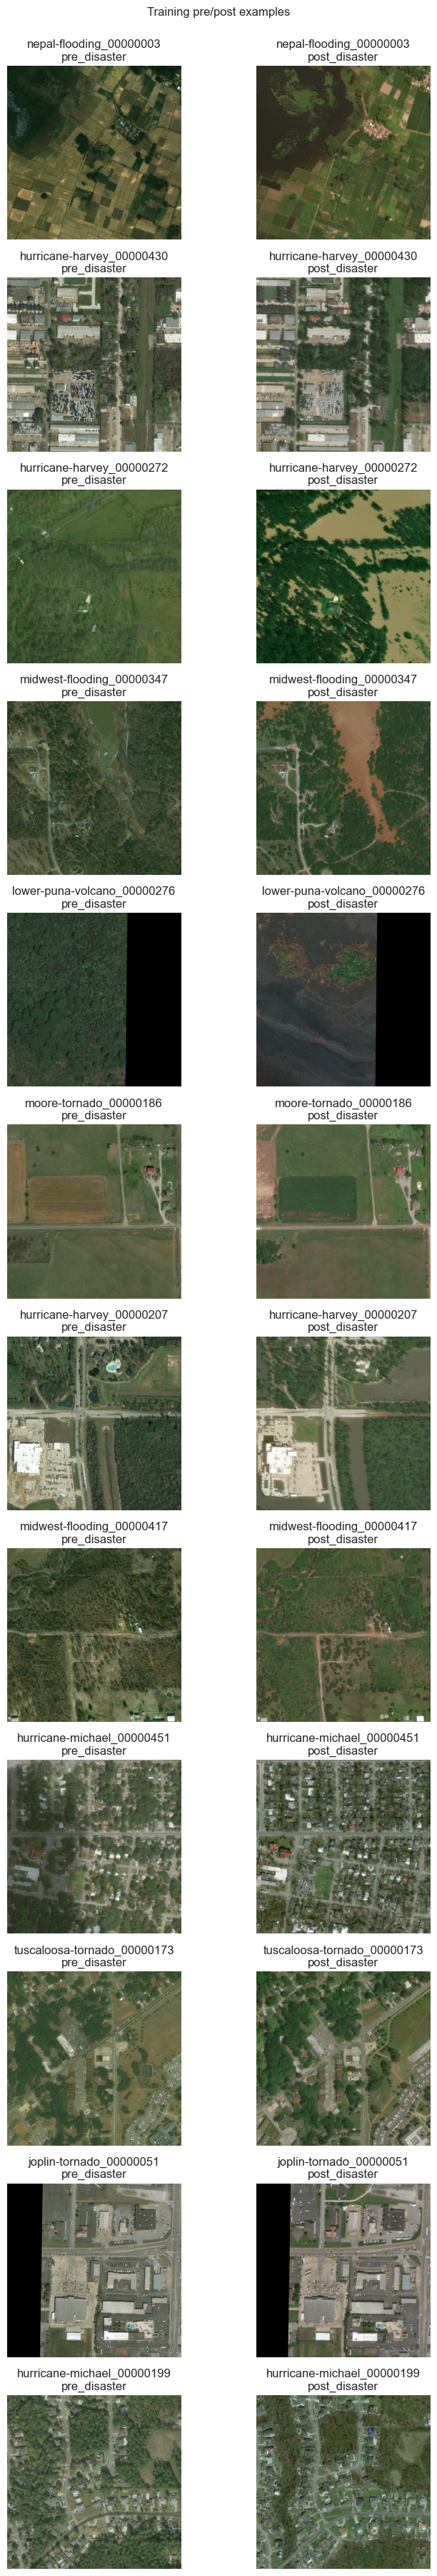

In [20]:
pair_index = image_index[(image_index['kind'].isin(['pre_disaster', 'post_disaster'])) & (image_index['split'] == 'train')].copy()
example_scenes = pair_index.drop_duplicates('scene_id').sample(min(IMAGE_SAMPLE_SIZE, pair_index.scene_id.nunique()), random_state=RANDOM_SEED)['scene_id']
example_rows = pair_index[pair_index['scene_id'].isin(example_scenes)].sort_values(['scene_id', 'kind'])

fig, axes = plt.subplots(len(example_scenes), 2, figsize=(8, max(3, len(example_scenes) * 3)), squeeze=False)
for row_index, scene_id in enumerate(example_scenes):
    scene_rows = example_rows[example_rows['scene_id'] == scene_id].set_index('kind')
    for column_index, kind in enumerate(['pre_disaster', 'post_disaster']):
        axis = axes[row_index, column_index]
        if kind in scene_rows.index:
            axis.imshow(Image.open(scene_rows.loc[kind, 'resolved_path']))
        axis.axis('off')
        axis.set_title(f'{scene_id}\n{kind}')
fig.suptitle('Training pre/post examples', y=1.0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'pre_post_examples_train.png', dpi=150)
plt.show()

## 9. Cleaning Decisions and Exported EDA Tables

This notebook keeps the original files unchanged. The cleaning checks are diagnostic: missing indexed files, inconsistent scene entries, missing damage subtypes, invalid geometries, extreme image-quality statistics, and suspicious near-duplicates are reported rather than silently repaired.

The generated CSV files and PNG figures are written to `results/eda`. Run `scripts/prepare_splits.py` separately when split creation or validation is needed.